In [1]:
import pm4py

log = pm4py.read_xes("/home/l/lixin/process_mining_topic_4/Sepsis Cases - Event Log_1_all/Sepsis Cases - Event Log.xes")

print("Events:", len(log))

print("Cases:", log["case:concept:name"].nunique())

print("Activities:", log["concept:name"].nunique())

print(log["concept:name"].unique())

variants = pm4py.get_variants(log)
print("Variants:", len(variants))

Events: 15214
Cases: 1050
Activities: 16
<StringArray>
[ 'ER Registration',       'Leucocytes',              'CRP',
       'LacticAcid',        'ER Triage', 'ER Sepsis Triage',
        'IV Liquid',   'IV Antibiotics',     'Admission NC',
        'Release A',        'Return ER',     'Admission IC',
        'Release B',        'Release C',        'Release D',
        'Release E']
Length: 16, dtype: str
Variants: 846




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing


/home/l/lixin/process_mining_topic_4/.venv/lib/python3.11/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(

parsing log, completed traces :: 100%|##########| 1050/1050 [00:00<00:00, 2887.41it/s]


In [2]:
cols = [
    "case:concept:name",
    "concept:name",
    "time:timestamp",
    "org:group",
    "Leucocytes",
    "CRP",
    "LacticAcid",
]

display(log[cols].head(30))

,case:concept:name,concept:name,time:timestamp,org:group,Leucocytes,CRP,LacticAcid
0,A,ER Registration,2014-10-22 09:15:41+00:00,A,NaN,NaN,NaN
1,A,Leucocytes,2014-10-22 09:27:00+00:00,B,9.6,NaN,NaN
2,A,CRP,2014-10-22 09:27:00+00:00,B,NaN,21.0,NaN
3,A,LacticAcid,2014-10-22 09:27:00+00:00,B,NaN,NaN,2.2
4,A,ER Triage,2014-10-22 09:33:37+00:00,C,NaN,NaN,NaN
5,A,ER Sepsis Triage,2014-10-22 09:34:00+00:00,A,NaN,NaN,NaN
6,A,IV Liquid,2014-10-22 12:03:47+00:00,A,NaN,NaN,NaN
7,A,IV Antibiotics,2014-10-22 12:03:47+00:00,A,NaN,NaN,NaN
8,A,Admission NC,2014-10-22 12:13:19+00:00,D,NaN,NaN,NaN
9,A,CRP,2014-10-24 07:00:00+00:00,B,NaN,109.0,NaN


## Process models at different thresholds

Run Inductive Miner and Heuristics Miner on the existing Sepsis event log `log`.

- Thresholds: `0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0` (increments of 0.1).
- **Inductive Miner**: set `noise_threshold` to filter infrequent behavior; `0` disables noise filtering.
- **Heuristics Miner**: set `dependency_threshold` to select dependencies between activities; keep all other parameters at their PM4Py defaults.

These parameters have different meanings: equal values do not imply equal filtering strength, and different thresholds may produce the same structure. Keep the actual discovery results for `1.0` rather than substituting another value. At this extreme, Heuristics Miner may produce very sparse models, although default rules such as those for short loops still apply.

Represent all results as **Petri nets** for comparison and subsequent analysis. `models[algorithm_name][threshold]` stores `(net, initial_marking, final_marking)`. PNG images, PNML models, and summary tables are saved in the project's `process_models/` directory.

Parameter reference: [PM4Py official documentation](https://processintelligence.solutions/app/pm4py/api/api/pm4py.discovery.html).

The summary table in cell 3 also includes a classic Alpha Miner baseline; its threshold is not applicable and is displayed as blank.

Additional models include ILP Miner with `alpha=[0.25, 0.5, 0.75, 1.0]` and default Split Miner (classic, epsilon=0.1, eta=0.4, minimize_or_joins=True). Split saves both the original BPMN model and the Petri net used for consistent evaluation. ILP alpha has a different meaning from the thresholds of the other algorithms.



In [30]:
from pathlib import Path
from time import perf_counter

import json
import pandas as pd
from IPython.display import Image, Markdown, display

def experiment_model_name(miner, parameter):
    if miner == "alpha":
        return "alpha"
    if miner == "split":
        return "split_default"
    if miner == "ilp":
        return f"ilp_alpha_{parameter:.2f}"
    return f"{miner}_threshold_{parameter:.1f}"

thresholds = [i / 10 for i in range(11)]  # 0.0 to 1.0 in increments of 0.1
# Support running the notebook from the project directory or its parent.
project_dir = Path.cwd()
if not (project_dir / "data.ipynb").exists():
    project_dir = project_dir / "process_mining_topic_4"
if not (project_dir / "data.ipynb").exists():
    raise FileNotFoundError("请在 process_mining_topic_4 项目目录或其父目录运行 notebook。")
output_dir = project_dir / "process_models"
output_dir.mkdir(parents=True, exist_ok=True)

models = {"inductive": {}, "heuristics": {}}
model_files = {"inductive": {}, "heuristics": {}}
summary_rows = []

miners = {
    "inductive": (pm4py.discover_petri_net_inductive, "noise_threshold"),
    "heuristics": (pm4py.discover_petri_net_heuristics, "dependency_threshold"),
}

for miner_name, (discover, parameter_name) in miners.items():
    miner_dir = output_dir / miner_name
    miner_dir.mkdir(parents=True, exist_ok=True)

    for threshold in thresholds:
        started = perf_counter()
        net, initial_marking, final_marking = discover(
            log, **{parameter_name: threshold}
        )
        discovery_seconds = perf_counter() - started
        models[miner_name][threshold] = (net, initial_marking, final_marking)

        stem = f"{miner_name}_threshold_{threshold:.1f}"
        pnml_path = miner_dir / f"{stem}.pnml"
        png_path = miner_dir / f"{stem}.png"
        pm4py.write_pnml(net, initial_marking, final_marking, str(pnml_path))
        pm4py.save_vis_petri_net(
            net, initial_marking, final_marking, str(png_path),
            graph_title=f"{miner_name} | {parameter_name}={threshold:.1f}",
        )
        model_files[miner_name][threshold] = {"pnml": pnml_path, "png": png_path}

        visible_transitions = sum(t.label is not None for t in net.transitions)
        summary_rows.append({
            "miner": miner_name,
            "threshold_parameter": parameter_name,
            "threshold": threshold,
            "places": len(net.places),
            "transitions": len(net.transitions),
            "visible_transitions": visible_transitions,
            "silent_transitions": len(net.transitions) - visible_transitions,
            "arcs": len(net.arcs),
            "discovery_seconds": round(discovery_seconds, 3),
            "pnml_file": str(pnml_path.relative_to(project_dir)),
            "png_file": str(png_path.relative_to(project_dir)),
        })
        print(f"{miner_name:10s} | {parameter_name}={threshold:.1f} | "
              f"places={len(net.places)}, transitions={len(net.transitions)}, arcs={len(net.arcs)}")

# Classic Alpha Miner has no threshold; use None for not applicable.
alpha_dir = output_dir / "alpha"
alpha_dir.mkdir(parents=True, exist_ok=True)
started = perf_counter()
alpha_net, alpha_im, alpha_fm = pm4py.discover_petri_net_alpha(log)
alpha_discovery_seconds = perf_counter() - started
models["alpha"] = {None: (alpha_net, alpha_im, alpha_fm)}
alpha_png = alpha_dir / "alpha.png"
alpha_pnml = alpha_dir / "alpha.pnml"
pm4py.write_pnml(alpha_net, alpha_im, alpha_fm, str(alpha_pnml))
pm4py.save_vis_petri_net(
    alpha_net, alpha_im, alpha_fm, str(alpha_png), graph_title="Alpha Miner (classic)",
)
model_files["alpha"] = {None: {"png": alpha_png, "pnml": alpha_pnml}}
alpha_visible = sum(t.label is not None for t in alpha_net.transitions)
alpha_row = {
    "miner": "alpha", "threshold_parameter": "not_applicable", "threshold": None,
    "places": len(alpha_net.places), "transitions": len(alpha_net.transitions),
    "visible_transitions": alpha_visible,
    "silent_transitions": len(alpha_net.transitions) - alpha_visible,
    "arcs": len(alpha_net.arcs), "discovery_seconds": alpha_discovery_seconds,
    "pnml_file": str(alpha_pnml.relative_to(project_dir)),
    "png_file": str(alpha_png.relative_to(project_dir)),
}

summary_rows.append(alpha_row)

# ILP Miner: alpha controls noise filtering; 1.0 disables filtering.
ilp_alphas = [0.25, 0.5, 0.75, 1.0]
models["ilp"] = {}
model_files["ilp"] = {}
models["split"] = {}
model_files["split"] = {}
for extra_miner, extra_parameters in [("ilp", ilp_alphas), ("split", [None])]:
    extra_dir = output_dir / extra_miner
    extra_dir.mkdir(parents=True, exist_ok=True)
    for extra_parameter in extra_parameters:
        extra_name = experiment_model_name(extra_miner, extra_parameter)
        print(f"Discovering {extra_name} ...", flush=True)
        extra_started = perf_counter()
        if extra_miner == "ilp":
            extra_net, extra_im, extra_fm = pm4py.discover_petri_net_ilp(log, alpha=extra_parameter)
            extra_discovery_seconds = perf_counter() - extra_started
            extra_conversion_seconds = 0.0
            extra_defaults = {"alpha": extra_parameter}
        else:
            # Omit parameters to use the local PM4Py Split Miner defaults.
            split_bpmn = pm4py.discover_bpmn_split_miner(log)
            extra_discovery_seconds = perf_counter() - extra_started
            conversion_started = perf_counter()
            extra_net, extra_im, extra_fm = pm4py.convert_to_petri_net(split_bpmn)
            extra_conversion_seconds = perf_counter() - conversion_started
            pm4py.write_bpmn(split_bpmn, str(extra_dir / "split_default.bpmn"))
            pm4py.save_vis_bpmn(split_bpmn, str(extra_dir / "split_default_bpmn.png"))
            extra_defaults = {"epsilon": 0.1, "eta": 0.4, "minimize_or_joins": True, "variant": "classic"}
        models[extra_miner][extra_parameter] = (extra_net, extra_im, extra_fm)
        extra_pnml = extra_dir / f"{extra_name}.pnml"
        extra_png = extra_dir / f"{extra_name}.png"
        pm4py.write_pnml(extra_net, extra_im, extra_fm, str(extra_pnml))
        pm4py.save_vis_petri_net(extra_net, extra_im, extra_fm, str(extra_png), graph_title=extra_name)
        model_files[extra_miner][extra_parameter] = {"pnml": extra_pnml, "png": extra_png}
        extra_visible = sum(t.label is not None for t in extra_net.transitions)
        summary_rows.append({
            "miner": extra_miner, "threshold_parameter": "alpha" if extra_miner == "ilp" else "default",
            "threshold": extra_parameter, "places": len(extra_net.places),
            "transitions": len(extra_net.transitions), "visible_transitions": extra_visible,
            "silent_transitions": len(extra_net.transitions) - extra_visible,
            "arcs": len(extra_net.arcs), "discovery_seconds": extra_discovery_seconds,
            "conversion_seconds": extra_conversion_seconds,
            "parameters": json.dumps(extra_defaults),
            "pnml_file": str(extra_pnml.relative_to(project_dir)),
            "png_file": str(extra_png.relative_to(project_dir)),
        })
        print(f"Saved {extra_name}: places={len(extra_net.places)}, transitions={len(extra_net.transitions)}, arcs={len(extra_net.arcs)}", flush=True)

model_summary = pd.DataFrame(summary_rows)
model_summary.to_csv(output_dir / "model_summary.csv", index=False)
display(model_summary.drop(columns=["pnml_file", "png_file"]))
print(f"模型及统计表已保存到：{output_dir.resolve()}")


,miner,threshold_parameter,threshold,places,transitions,visible_transitions,silent_transitions,arcs,discovery_seconds,conversion_seconds,discovery_timing_status,parameters
0,inductive,noise_threshold,0.00,39,50,16,34,116,0.321000,NaN,NaN,NaN
1,inductive,noise_threshold,0.10,31,40,15,25,92,0.108000,NaN,NaN,NaN
2,inductive,noise_threshold,0.20,28,35,13,22,82,0.112000,NaN,NaN,NaN
3,inductive,noise_threshold,0.30,23,23,9,14,58,0.068000,NaN,NaN,NaN
4,inductive,noise_threshold,0.40,23,23,9,14,58,0.067000,NaN,NaN,NaN
5,inductive,noise_threshold,0.50,23,23,9,14,58,0.072000,NaN,NaN,NaN
6,inductive,noise_threshold,0.60,23,23,9,14,58,0.088000,NaN,NaN,NaN
7,inductive,noise_threshold,0.70,23,23,9,14,58,0.091000,NaN,NaN,NaN
8,inductive,noise_threshold,0.80,23,23,9,14,58,0.068000,NaN,NaN,NaN
9,inductive,noise_threshold,0.90,23,23,9,14,58,0.074000,NaN,NaN,NaN


### Inductive Miner: Petri nets at each noise threshold



In [ ]:
# for threshold in thresholds:
#     display(Markdown(f"#### Inductive Miner — noise_threshold = {threshold:.1f}"))
#     display(Image(filename=str(model_files["inductive"][threshold]["png"]), width=1200))


### Heuristics Miner: Petri nets at each dependency threshold



In [ ]:
# for threshold in thresholds:
#     display(Markdown(f"#### Heuristics Miner — dependency_threshold = {threshold:.1f}"))
#     display(Image(filename=str(model_files["heuristics"][threshold]["png"]), width=1200))


## Alpha Miner baseline

Add classic Alpha Miner using the same complete event log. This algorithm has no threshold parameter, so only one model is generated; the threshold is left blank in tables and represented by `None` in memory. The evaluation below compares this baseline with the 22 Inductive / Heuristics models.

Reference: [PM4Py Alpha Miner documentation](https://processintelligence.solutions/app/pm4py/api/api/pm4py.discovery.html).



In [ ]:
# The Alpha model was discovered and added to the combined summary in cell 3; display it here.
alpha_net, alpha_im, alpha_fm = models["alpha"][None]
alpha_png = model_files["alpha"][None]["png"]
alpha_pnml = model_files["alpha"][None]["pnml"]
# display(Image(filename=str(alpha_png), width=1200))
# display(model_summary.loc[model_summary["miner"] == "alpha"])


## Fitness, precision, and runtime for each model

Evaluate 28 models (22 Inductive/Heuristics, 1 Alpha, 4 ILP, and 1 default Split) on the complete original event log using **token-based replay fitness** and **ETConformance token-based precision** (PM4Py's `ETCONFORMANCE_TOKEN`).

- Per trace: save the original case ID, event count, `trace_fitness`, `trace_is_fit`, and missing/consumed/remaining/produced token counts.
- Entire event log: `fitness` uses PM4Py's `log_fitness`, computed as `0.5 × (1 − missing/consumed) + 0.5 × (1 − remaining/produced)` after aggregating token counts across all traces. Also save `average_trace_fitness`, the arithmetic mean of individual trace fitness values; these metrics must not be used interchangeably.
- `fitness_runtime` measures fitness replay and log-level aggregation; `precision_runtime` measures precision computation. Time them separately in seconds. Exclude log loading, log conversion, plotting, and file writing; discovery time is listed separately in the details. Obtain per-trace records from a single replay of the complete log, without replaying each trace again or inventing individual runtimes.
- Explicitly set `consider_remaining_in_fitness=True` to match PM4Py's standard token fitness, keeping other replay rules at their defaults. This replay method is heuristic. By default, PM4Py does not directly count activities absent from a model as missing tokens, so also record uncovered activities and their event counts for each model. Refer to these fields when interpreting scores for models that omit activities.
- Precision is based on successfully replayed prefixes; interpret precision for low-fitness models together with fitness. These results are descriptive evaluations on the same log.

Method reference: [PM4Py official examples](https://processintelligence.solutions/pm4py/examples/process-discovery).



In [10]:
import json
from pm4py.algo.conformance.tokenreplay import algorithm as token_replay
from pm4py.algo.evaluation.replay_fitness.variants import token_replay as token_fitness
from pm4py.algo.evaluation.precision import algorithm as precision_evaluator

# Reuse the converted EventLog to keep trace order aligned with replay results.
event_log = pm4py.convert_to_event_log(log, case_id_key="case:concept:name")
case_ids = [trace.attributes["concept:name"] for trace in event_log]
assert len(event_log) == log["case:concept:name"].nunique()
assert len(set(case_ids)) == len(case_ids)

evaluation_dir = output_dir / "evaluation"
trace_dir = evaluation_dir / "trace_fitness"
trace_dir.mkdir(parents=True, exist_ok=True)

trace_fitness_tables = {miner: {} for miner in models}
log_fitness_results = {miner: {} for miner in models}
evaluation_rows = []
all_trace_tables = []
activity_counts = log["concept:name"].value_counts()
replay_parameters = {
    "show_progress_bar": False,
    "consider_remaining_in_fitness": True,
}

for miner_name, models_by_threshold in models.items():
    for threshold, (net, initial_marking, final_marking) in models_by_threshold.items():
        model_name = experiment_model_name(miner_name, threshold)
        print(f"Evaluating {model_name} ...", flush=True)

        started = perf_counter()
        replay_results = token_replay.apply(
            event_log, net, initial_marking, final_marking,
            variant=token_replay.Variants.TOKEN_REPLAY,
            parameters=replay_parameters,
        )
        log_fitness = token_fitness.evaluate(replay_results)
        fitness_seconds = perf_counter() - started
        assert len(replay_results) == len(event_log)

        started = perf_counter()
        precision = precision_evaluator.apply(
            event_log, net, initial_marking, final_marking,
            variant=precision_evaluator.Variants.ETCONFORMANCE_TOKEN,
            parameters={"show_progress_bar": False},
        )
        precision_seconds = perf_counter() - started

        trace_rows = []
        for trace_index, (trace, replay) in enumerate(zip(event_log, replay_results)):
            trace_rows.append({
                "model": model_name,
                "miner": miner_name,
                "threshold": threshold,
                "trace_index": trace_index,
                "case_id": case_ids[trace_index],
                "events": len(trace),
                "trace_fitness": replay["trace_fitness"],
                "trace_is_fit": replay["trace_is_fit"],
                "missing_tokens": replay["missing_tokens"],
                "consumed_tokens": replay["consumed_tokens"],
                "remaining_tokens": replay["remaining_tokens"],
                "produced_tokens": replay["produced_tokens"],
            })
        traces = pd.DataFrame(trace_rows)
        trace_fitness_tables[miner_name][threshold] = traces
        log_fitness_results[miner_name][threshold] = log_fitness
        traces.to_csv(trace_dir / f"{model_name}_trace_fitness.csv", index=False)
        all_trace_tables.append(traces)

        discovery_seconds = float(model_summary.loc[
            (model_summary["miner"] == miner_name)
            & (model_summary["threshold"].isna() if threshold is None
               else model_summary["threshold"] == threshold), "discovery_seconds"
        ].iloc[0])
        covered_activities = {t.label for t in net.transitions if t.label is not None}
        uncovered_activities = sorted(set(activity_counts.index) - covered_activities)
        evaluation_rows.append({
            "model": model_name,
            "fitness": log_fitness["log_fitness"],
            "precision": float(precision),
            "fitness_runtime": fitness_seconds,
            "precision_runtime": precision_seconds,
            "miner": miner_name,
            "threshold": threshold,
            "average_trace_fitness": log_fitness["average_trace_fitness"],
            "percentage_of_fitting_traces": log_fitness["percentage_of_fitting_traces"],
            "traces": len(traces),
            "fitness_seconds": fitness_seconds,
            "precision_seconds": precision_seconds,
            "discovery_seconds": discovery_seconds,
            "discovery_and_evaluation_seconds": discovery_seconds + fitness_seconds + precision_seconds,
            "uncovered_activities": json.dumps(uncovered_activities, ensure_ascii=False),
            "uncovered_events": int(activity_counts.reindex(uncovered_activities).sum()),
        })
        print(f"  fitness={log_fitness['log_fitness']:.6f}, precision={precision:.6f}, "
              f"fitness_runtime={fitness_seconds:.3f}s, precision_runtime={precision_seconds:.3f}s", flush=True)

trace_fitness_all = pd.concat(all_trace_tables, ignore_index=True)
evaluation_details = pd.DataFrame(evaluation_rows)
evaluation_summary = evaluation_details[["model", "fitness", "precision", "fitness_runtime", "precision_runtime"]].copy()

trace_fitness_all.to_csv(evaluation_dir / "trace_fitness_all.csv", index=False)
evaluation_details.to_csv(evaluation_dir / "evaluation_details.csv", index=False)
evaluation_summary.to_csv(evaluation_dir / "evaluation_summary.csv", index=False)
print(f"评估结果保存到：{evaluation_dir.resolve()}")


Evaluating inductive_threshold_0.2 ...
  fitness=0.987239, precision=0.452476, fitness_runtime=0.866s, precision_runtime=10.878s
Evaluating inductive_threshold_0.4 ...
  fitness=0.945377, precision=0.492646, fitness_runtime=0.886s, precision_runtime=8.840s
Evaluating inductive_threshold_0.6 ...
  fitness=0.945377, precision=0.492646, fitness_runtime=0.830s, precision_runtime=8.999s
Evaluating inductive_threshold_0.8 ...
  fitness=0.945377, precision=0.492646, fitness_runtime=0.839s, precision_runtime=8.932s
Evaluating inductive_threshold_0.9 ...
  fitness=0.945377, precision=0.492646, fitness_runtime=0.829s, precision_runtime=8.755s
Evaluating heuristics_threshold_0.2 ...
  fitness=0.818069, precision=0.959378, fitness_runtime=1.471s, precision_runtime=2.467s
Evaluating heuristics_threshold_0.4 ...
  fitness=0.883044, precision=0.800342, fitness_runtime=1.308s, precision_runtime=3.384s
Evaluating heuristics_threshold_0.6 ...
  fitness=0.934135, precision=0.539405, fitness_runtime=1.278

### Summary table

`fitness` is the token replay fitness of the entire log; `fitness_runtime` and `precision_runtime` are the respective computation times in seconds. The CSV retains the original values; only the display below is formatted.



In [31]:
display(evaluation_summary.round({"fitness": 6, "precision": 6, "fitness_runtime": 3, "precision_runtime": 3}))


,model,fitness,precision,fitness_runtime,precision_runtime
0,inductive_threshold_0.0,1.000000,0.257621,1.252,19.984
1,inductive_threshold_0.1,0.996331,0.418473,0.989,13.799
2,inductive_threshold_0.2,0.987239,0.452476,0.866,10.878
3,inductive_threshold_0.3,0.945377,0.492646,0.892,8.799
4,inductive_threshold_0.4,0.945377,0.492646,0.886,8.840
5,inductive_threshold_0.5,0.945377,0.492646,0.823,8.819
6,inductive_threshold_0.6,0.945377,0.492646,0.830,8.999
7,inductive_threshold_0.7,0.945377,0.492646,0.829,8.763
8,inductive_threshold_0.8,0.945377,0.492646,0.839,8.932
9,inductive_threshold_0.9,0.945377,0.492646,0.829,8.755


### Per-trace fitness and runtime details

The first 12 per-trace results are shown below. Complete records are available in `process_models/evaluation/trace_fitness_all.csv`, with separate files for each model in the `trace_fitness/` subdirectory. For example, `trace_fitness_tables["inductive"][0.3]` contains all traces for that model.

When reloading per-trace CSV files, use `pd.read_csv(path, dtype={"case_id": str}, keep_default_na=False)` to preserve original case IDs (the log contains strings such as `NA` that Pandas interprets as missing values by default).



In [32]:
display(trace_fitness_all.head(12))
display(evaluation_details[[
    "model", "average_trace_fitness", "percentage_of_fitting_traces",
    "fitness_runtime", "precision_runtime", "discovery_seconds",
    "discovery_and_evaluation_seconds", "uncovered_activities", "uncovered_events",
]])

# Ensure every model records all original cases and aggregates match per-trace token counts.
expected_models = sum(len(by_threshold) for by_threshold in models.values())
assert len(evaluation_summary) == expected_models == 28
assert len(trace_fitness_all) == expected_models * len(event_log)
for _, result in evaluation_details.iterrows():
    threshold_key = None if pd.isna(result["threshold"]) else result["threshold"]
    traces = trace_fitness_tables[result["miner"]][threshold_key]
    assert traces["case_id"].tolist() == case_ids
    assert traces["trace_fitness"].between(0, 1).all()
    assert 0 <= result["fitness"] <= 1 and 0 <= result["precision"] <= 1
    assert abs(traces["trace_fitness"].mean() - result["average_trace_fitness"]) < 1e-12
    expected_fitness = (
        0.5 * (1 - traces["missing_tokens"].sum() / traces["consumed_tokens"].sum())
        + 0.5 * (1 - traces["remaining_tokens"].sum() / traces["produced_tokens"].sum())
    )
    assert abs(expected_fitness - result["fitness"]) < 1e-12
    assert result["fitness_runtime"] >= 0
    assert result["precision_runtime"] >= 0
print(f"验证通过：{expected_models} 个模型，每个模型 {len(event_log)} 条 trace，"
      f"共 {len(trace_fitness_all)} 条 trace fitness 记录。")


验证通过：28 个模型，每个模型 1050 条 trace，共 29400 条 trace fitness 记录。


,model,miner,threshold,trace_index,case_id,events,trace_fitness,trace_is_fit,missing_tokens,consumed_tokens,remaining_tokens,produced_tokens
0,inductive_threshold_0.0,inductive,0,0,A,22,1.0,True,0,61,0,61
1,inductive_threshold_0.0,inductive,0,1,B,12,1.0,True,0,41,0,41
2,inductive_threshold_0.0,inductive,0,2,C,14,1.0,True,0,45,0,45
3,inductive_threshold_0.0,inductive,0,3,D,13,1.0,True,0,41,0,41
4,inductive_threshold_0.0,inductive,0,4,E,8,1.0,True,0,35,0,35
5,inductive_threshold_0.0,inductive,0,5,F,10,1.0,True,0,37,0,37
6,inductive_threshold_0.0,inductive,0,6,G,12,1.0,True,0,41,0,41
7,inductive_threshold_0.0,inductive,0,7,H,13,1.0,True,0,47,0,47
8,inductive_threshold_0.0,inductive,0,8,I,11,1.0,True,0,41,0,41
9,inductive_threshold_0.0,inductive,0,9,J,11,1.0,True,0,39,0,39


,model,average_trace_fitness,percentage_of_fitting_traces,fitness_runtime,precision_runtime,discovery_seconds,discovery_and_evaluation_seconds,uncovered_activities,uncovered_events
0,inductive_threshold_0.0,1.000000,100.000000,1.252219,19.983832,0.314000,21.550051,[],0
1,inductive_threshold_0.1,0.993504,93.047619,0.989359,13.798577,0.104000,14.891936,"[""Release B""]",56
2,inductive_threshold_0.2,0.979645,80.380952,0.866420,10.877538,0.112000,11.855958,"[""Admission IC"", ""Release B"", ""Release E""]",179
3,inductive_threshold_0.3,0.905391,57.904762,0.891639,8.799327,0.075000,9.765966,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193
4,inductive_threshold_0.4,0.905391,57.904762,0.885761,8.840497,0.067000,9.793258,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193
5,inductive_threshold_0.5,0.905391,57.904762,0.822653,8.819425,0.064000,9.706079,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193
6,inductive_threshold_0.6,0.905391,57.904762,0.829615,8.999356,0.088000,9.916971,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193
7,inductive_threshold_0.7,0.905391,57.904762,0.828975,8.762611,0.067000,9.658586,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193
8,inductive_threshold_0.8,0.905391,57.904762,0.838520,8.932146,0.068000,9.838666,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193
9,inductive_threshold_0.9,0.905391,57.904762,0.828860,8.755046,0.074000,9.657906,"[""Admission IC"", ""Release A"", ""Release B"", ""Re...",1193


## Fitness and precision visualizations

Read the existing evaluation table and plot all 28 models. The scatter plot shows log-level fitness on the horizontal axis and precision on the vertical axis; points closer to the upper-right corner have higher values for both metrics. Labels indicate thresholds. Combine labels for identical coordinates so overlapping models are not mistaken for missing ones.

Line plots show how fitness and precision vary with the threshold. Alpha and default Split have no threshold to sweep, so they appear as horizontal dashed and dotted baselines, respectively; ILP is labeled separately with its alpha parameter. Keep the actual results for threshold=1.0. Export figures as both PNG and SVG to `process_models/evaluation/plots/`.



In [33]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from IPython.display import Image, display

# Read saved evaluation results without rediscovering or reevaluating models.
plot_project_dir = Path.cwd()
if not (plot_project_dir / "data.ipynb").exists():
    plot_project_dir = plot_project_dir / "process_mining_topic_4"
plot_evaluation_dir = plot_project_dir / "process_models" / "evaluation"
plot_dir = plot_evaluation_dir / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)
plot_data = pd.read_csv(plot_evaluation_dir / "evaluation_details.csv")
plot_data["threshold"] = pd.to_numeric(plot_data["threshold"], errors="coerce")
assert len(plot_data) == 28 and plot_data["model"].is_unique
assert plot_data[["fitness", "precision"]].ge(0).all().all()
assert plot_data[["fitness", "precision"]].le(1).all().all()
for miner in ["inductive", "heuristics"]:
    assert sorted(plot_data.loc[plot_data["miner"] == miner, "threshold"]) == [i / 10 for i in range(11)]

plot_colors = {"inductive": "#2563eb", "heuristics": "#d97706", "alpha": "#7c3aed", "ilp": "#dc2626", "split": "#0f766e"}
plot_names = {"inductive": "Inductive Miner", "heuristics": "Heuristics Miner", "alpha": "Alpha Miner", "ilp": "ILP Miner", "split": "Split Miner (default)"}
plot_markers = {"inductive": "o", "heuristics": "s", "alpha": "*", "ilp": "^", "split": "D"}


def save_evaluation_plot(fig, stem):
    fig.savefig(plot_dir / f"{stem}.png", dpi=220, bbox_inches="tight", facecolor="white")
    fig.savefig(plot_dir / f"{stem}.svg", bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(plot_dir / f"{stem}.png"), width=1200))


### Fitness–precision scatter plot: High / Low regions

Use fitness=0.5 and precision=0.5 as boundaries, with four light background colors distinguishing High/High, High/Low, Low/High, and Low/Low. Scores ≥0.5 are classified as High. Here, 0.5 is the specified plotting boundary, not an algorithm threshold or a universal quality standard. Point colors and shapes still identify algorithms, and labels indicate algorithm thresholds.



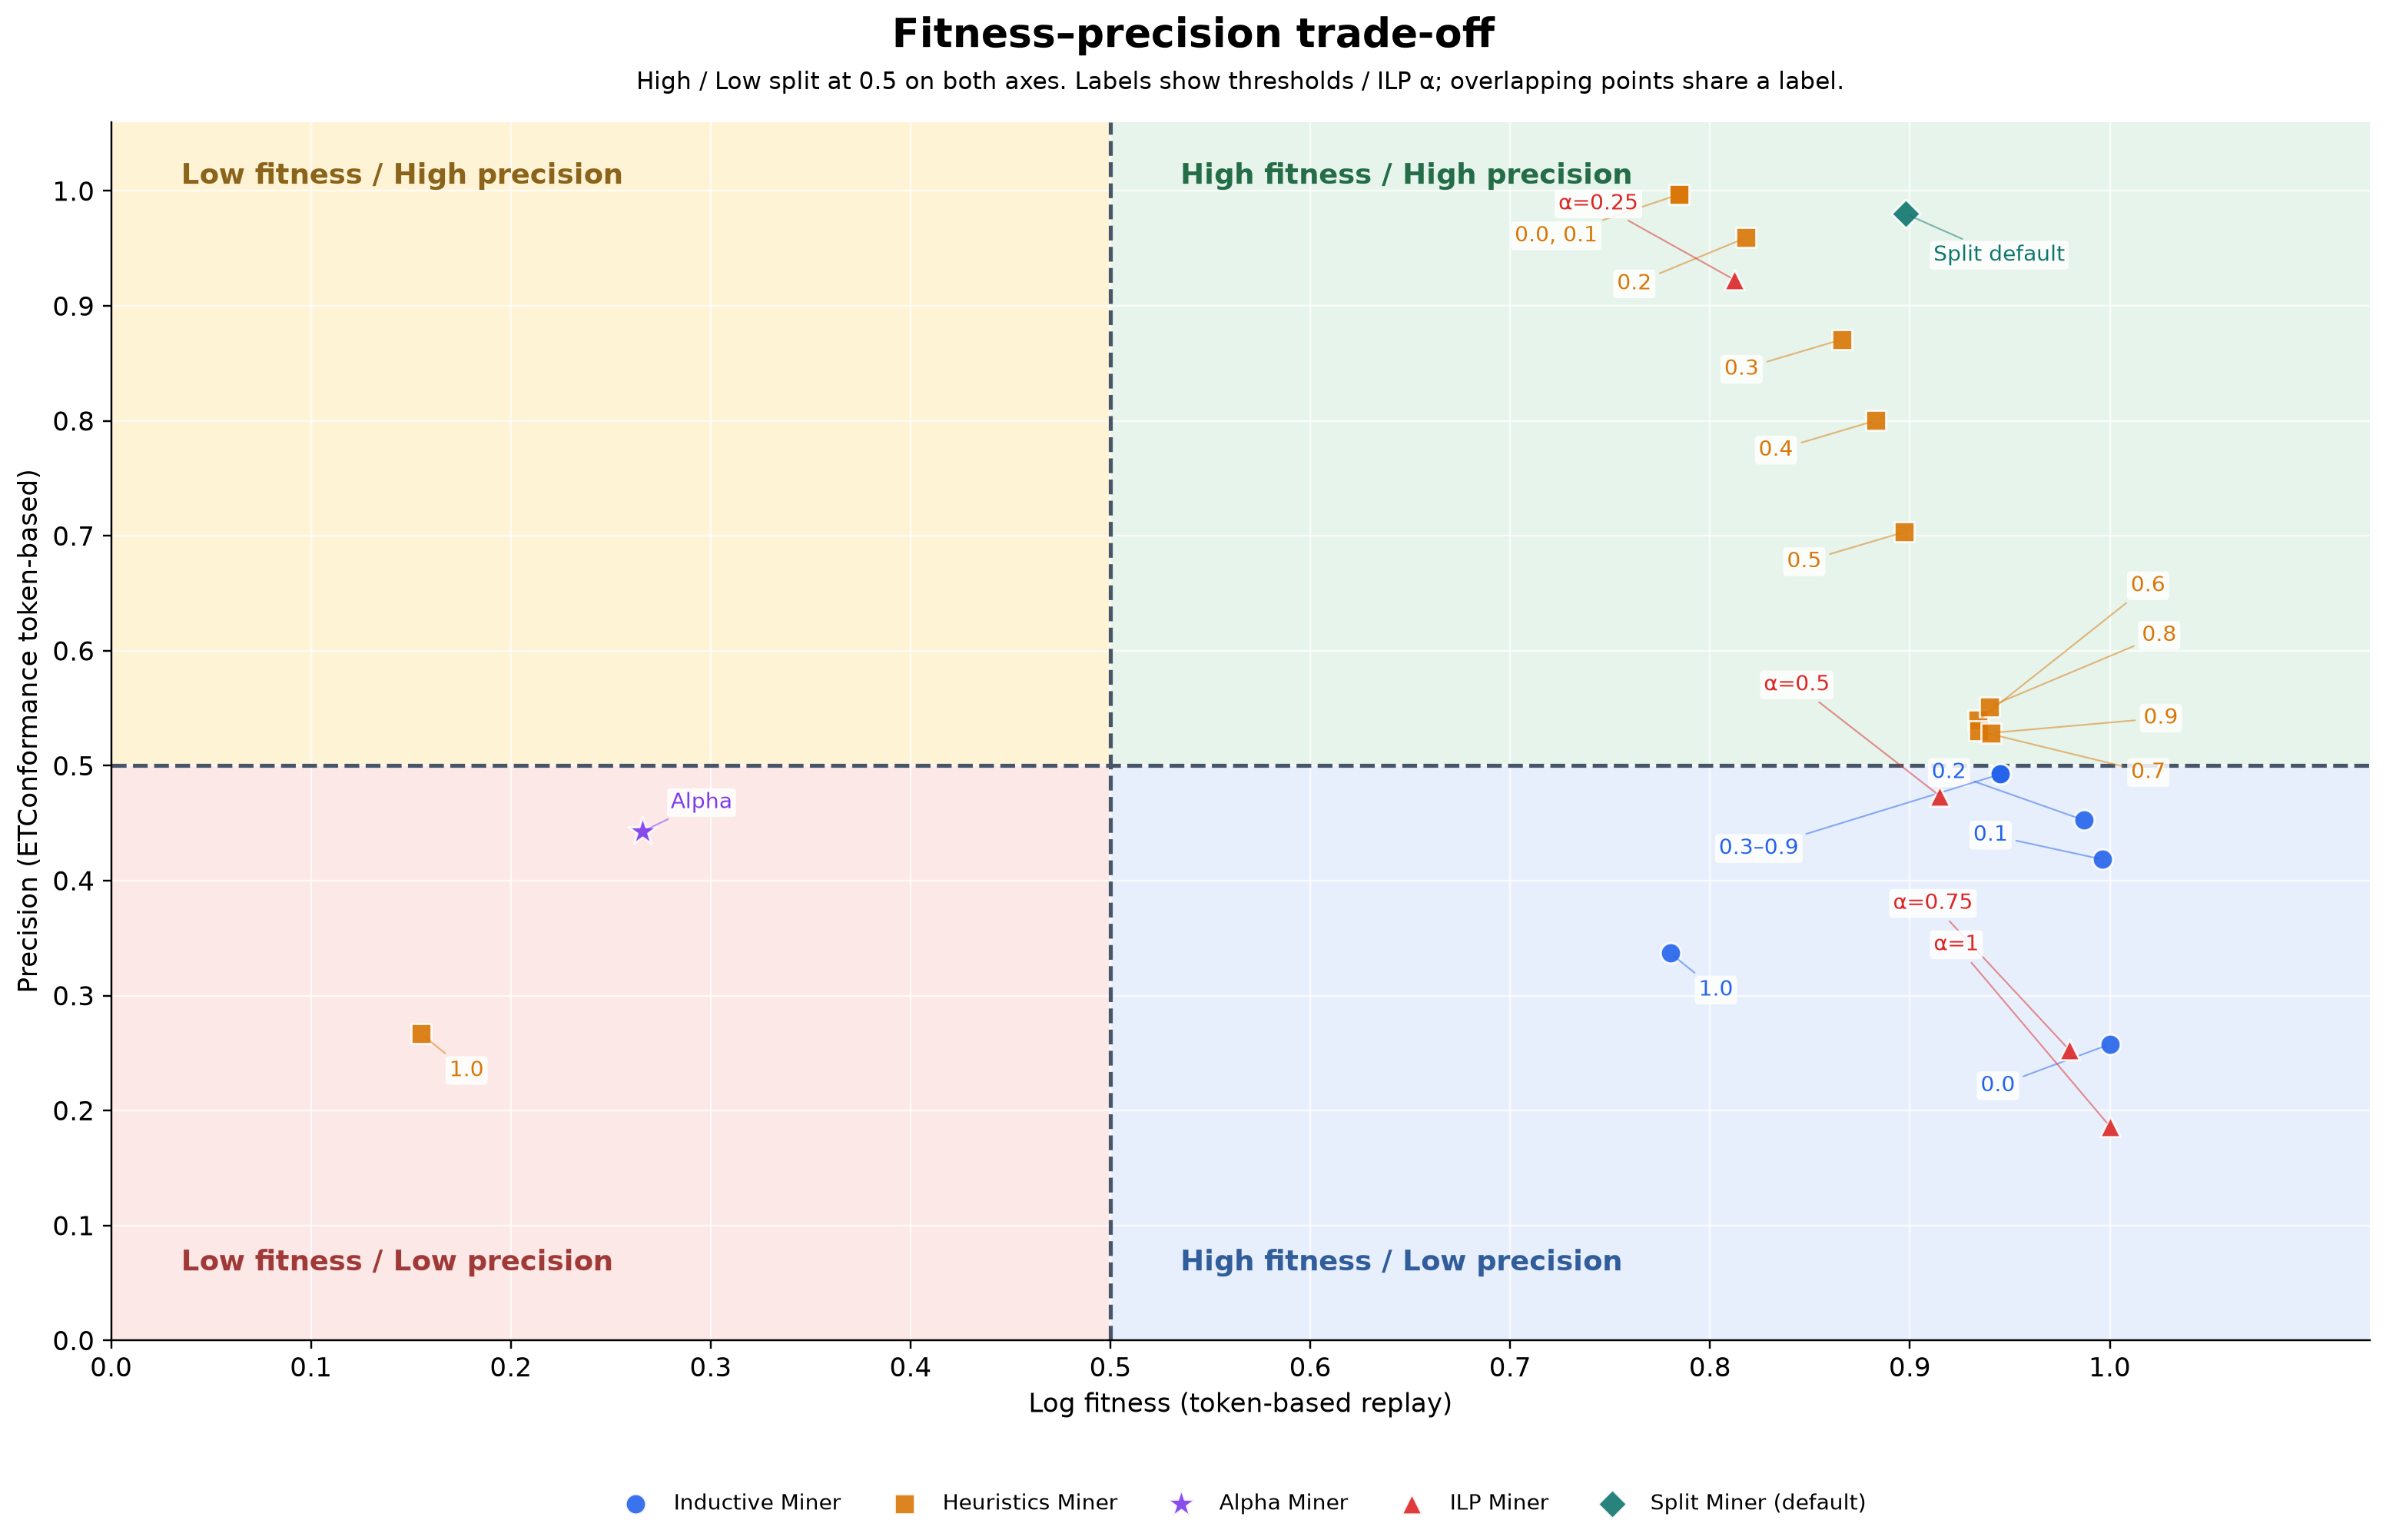

In [34]:
with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    from matplotlib.patches import Rectangle
    fig, ax = plt.subplots(figsize=(14, 9), layout="constrained")
    # Use 0.5 as the boundary for this plot only; classify scores >= 0.5 as High.
    quadrant_specs = [
        ((0, 0), 0.5, 0.5, "#fce8e6", (0.035, 0.055), "Low fitness / Low precision", "#9f3a38"),
        ((0, 0.5), 0.5, 0.56, "#fff3d6", (0.035, 1.025), "Low fitness / High precision", "#8a641b"),
        ((0.5, 0), 0.63, 0.5, "#e8effc", (0.535, 0.055), "High fitness / Low precision", "#315d9b"),
        ((0.5, 0.5), 0.63, 0.56, "#e6f4eb", (0.535, 1.025), "High fitness / High precision", "#256c48"),
    ]
    for origin, width, height, color, label_position, label, label_color in quadrant_specs:
        ax.add_patch(Rectangle(origin, width, height, facecolor=color, edgecolor="none", zorder=0))
        ax.text(*label_position, label, color=label_color, fontsize=12,
                fontweight="bold", va="top" if label_position[1] > 0.5 else "bottom", zorder=2)
    ax.axvline(0.5, color="#475569", linestyle="--", linewidth=1.7, zorder=2)
    ax.axhline(0.5, color="#475569", linestyle="--", linewidth=1.7, zorder=2)
    # Combine only points with identical coordinates; keep actual data positions unchanged.
    for miner in ["inductive", "heuristics", "alpha", "ilp", "split"]:
        subset = plot_data.loc[plot_data["miner"] == miner].sort_values("threshold")
        ax.scatter(subset["fitness"], subset["precision"],
                   s=160 if miner == "alpha" else 75, marker=plot_markers[miner],
                   color=plot_colors[miner], edgecolor="white", linewidth=0.9,
                   alpha=0.9, label=plot_names[miner], zorder=3)
        for (fitness, precision), group in subset.groupby(["fitness", "precision"], sort=False):
            values = group["threshold"].dropna().sort_values().tolist()
            if miner in ["alpha", "split"]:
                label, offset = ("Alpha", (12, 10)) if miner == "alpha" else ("Split default", (12, -20))
            else:
                label = ", ".join(f"{v:g}" if miner == "ilp" else f"{v:.1f}" for v in values)
                if len(values) > 2 and all(abs(b - a - 0.1) < 1e-9 for a, b in zip(values, values[1:])):
                    label = f"{values[0]:.1f}–{values[-1]:.1f}"
                threshold = values[0]
                if miner == "ilp":
                    label = "α=" + label
                    offsets = {0.25: (-75, 30), 0.5: (-75, 45), 0.75: (-75, 60), 1.0: (-75, 75)}
                elif miner == "inductive":
                    offsets = {0.0: (-55, -20), 0.1: (-55, 8), 0.2: (-65, 18), 0.3: (-120, -34), 1.0: (12, -18)}
                else:
                    offsets = {0.0: (-70, -20), 0.2: (-55, -22), 0.3: (-50, -15), 0.4: (-50, -15),
                               0.5: (-50, -15), 0.6: (65, 55), 0.7: (65, -20), 0.8: (65, 28),
                               0.9: (65, 4), 1.0: (12, -18)}
                offset = offsets.get(threshold, (12, 10))
            ax.annotate(label, (fitness, precision), xytext=offset, textcoords="offset points",
                        fontsize=9, color=plot_colors[miner],
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.85},
                        arrowprops={"arrowstyle": "-", "color": plot_colors[miner], "alpha": 0.5, "lw": 0.7})
    ax.set(xlabel="Log fitness (token-based replay)", ylabel="Precision (ETConformance token-based)",
           xlim=(0, 1.13), ylim=(0, 1.06))
    ax.set_xticks([i / 10 for i in range(11)])
    ax.set_yticks([i / 10 for i in range(11)])
    ax.grid(color="white", alpha=0.75, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=5, frameon=False, fontsize=9)
    fig.suptitle("Fitness–precision trade-off", fontsize=17, fontweight="bold")
    ax.set_title("High / Low split at 0.5 on both axes. Labels show thresholds / ILP α; overlapping points share a label.", fontsize=10, pad=14)
    save_evaluation_plot(fig, "fitness_precision_scatter")


### Fitness and precision at different thresholds

Inductive Miner uses a noise threshold; Heuristics Miner uses a dependency threshold; ILP uses alpha (0.25, 0.5, 0.75, 1.0). These values have different meanings. Alpha and default Split appear as horizontal reference lines. Connecting lines only help readers follow the discrete values; they do not imply that intermediate thresholds were evaluated.



PNG 与 SVG 图已保存到：/home/l/lixin/process_mining_topic_4/process_models/evaluation/plots


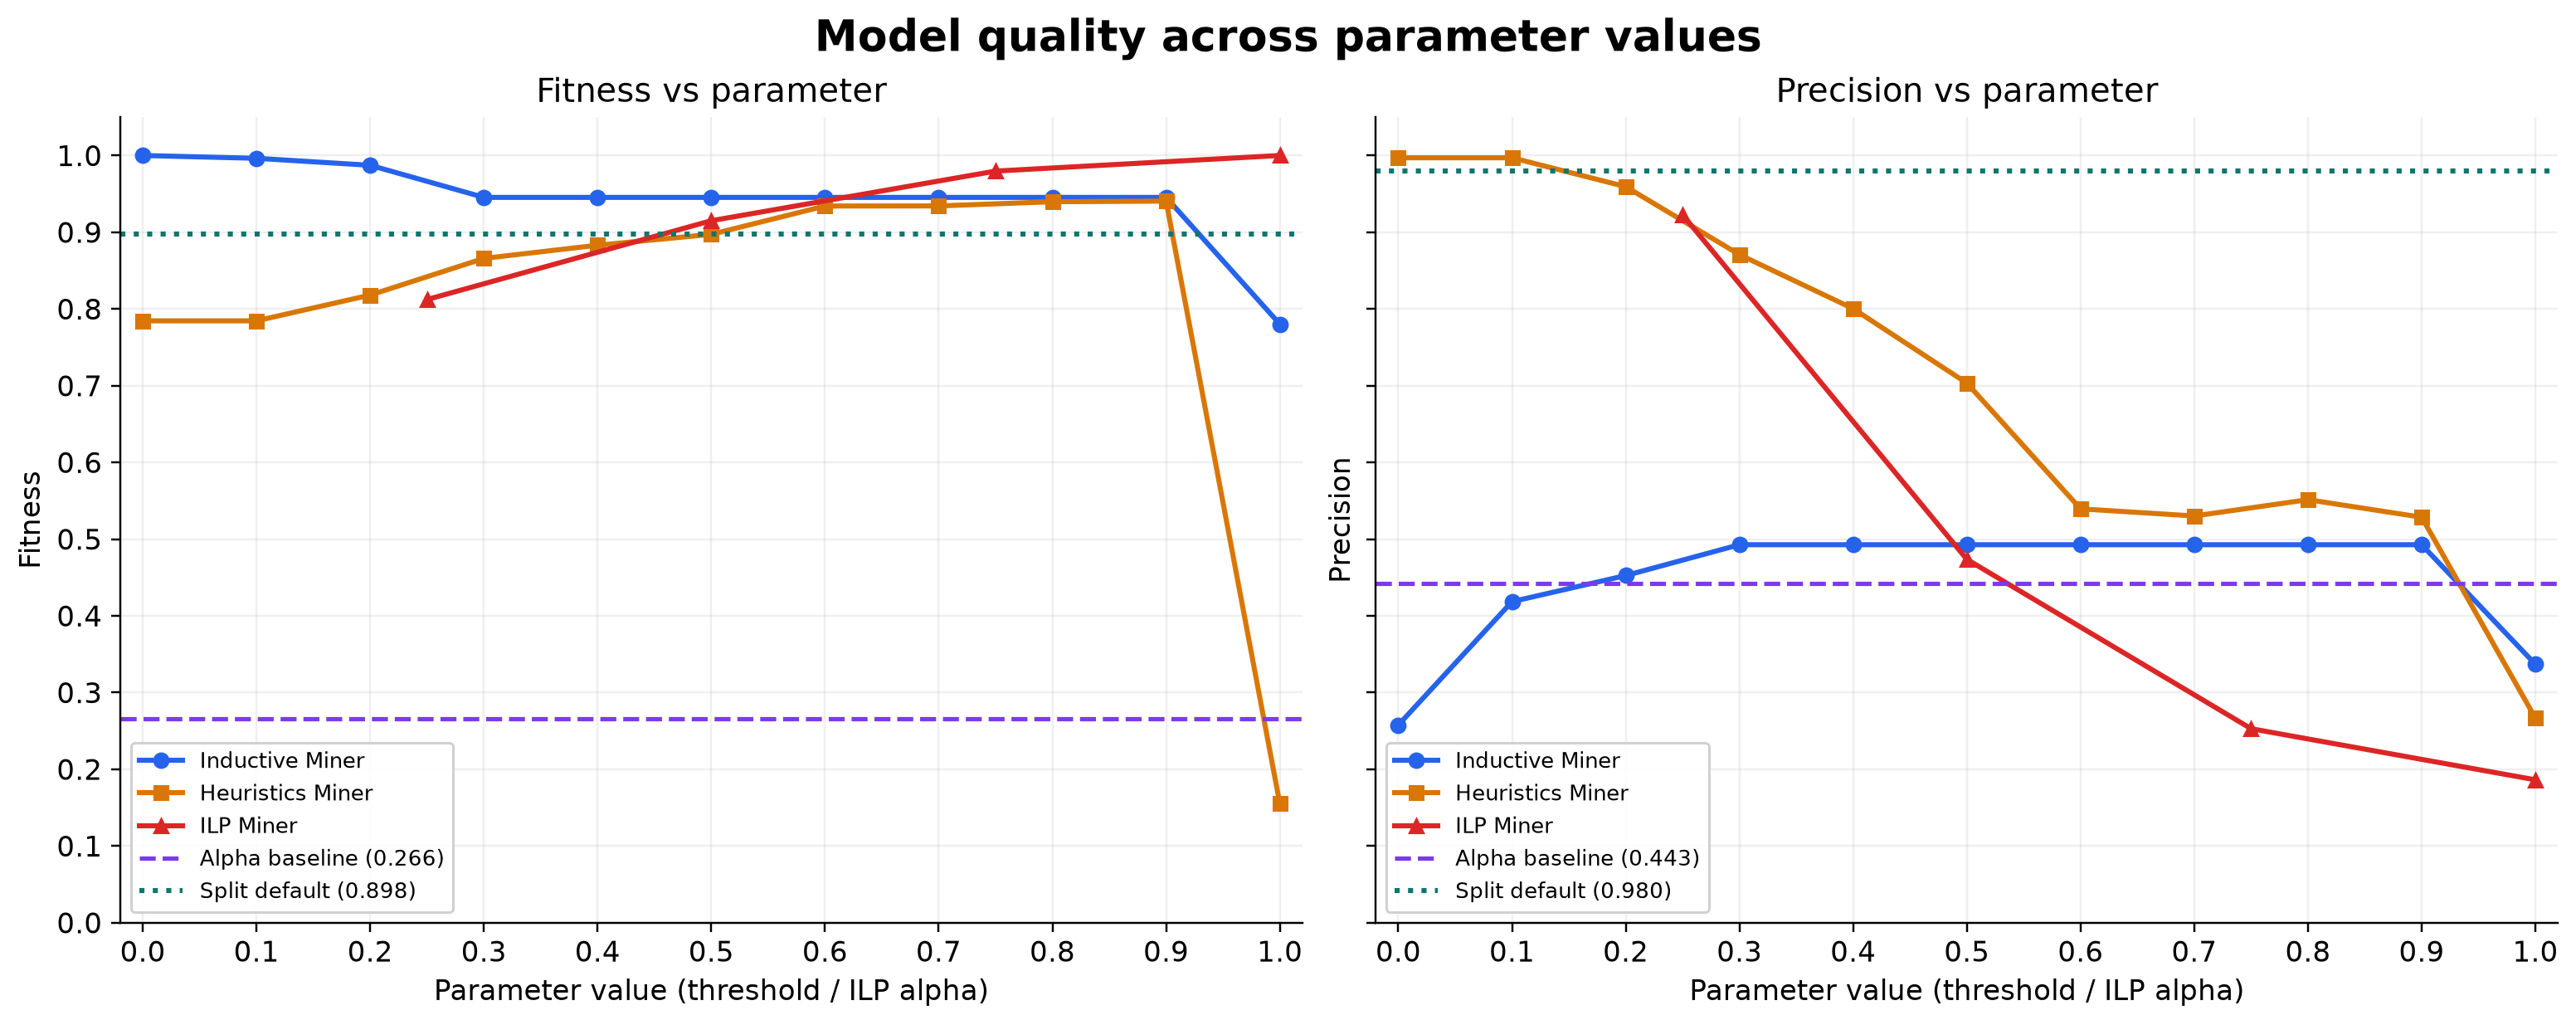

In [35]:
with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True, layout="constrained")
    for ax, metric, title in zip(axes, ["fitness", "precision"], ["Fitness vs parameter", "Precision vs parameter"]):
        for miner in ["inductive", "heuristics", "ilp"]:
            subset = plot_data.loc[plot_data["miner"] == miner].sort_values("threshold")
            ax.plot(subset["threshold"], subset[metric], color=plot_colors[miner],
                    marker=plot_markers[miner], markersize=5.5, linewidth=2, label=plot_names[miner])
        alpha_value = plot_data.loc[plot_data["miner"] == "alpha", metric].iloc[0]
        ax.axhline(alpha_value, color=plot_colors["alpha"], linestyle="--", linewidth=1.7,
                   label=f"Alpha baseline ({alpha_value:.3f})")
        split_value = plot_data.loc[plot_data["miner"] == "split", metric].iloc[0]
        ax.axhline(split_value, color=plot_colors["split"], linestyle=":", linewidth=2,
                   label=f"Split default ({split_value:.3f})")
        ax.set(title=title, xlabel="Parameter value (threshold / ILP alpha)", ylabel=metric.capitalize(), xlim=(-0.02, 1.02), ylim=(0, 1.05))
        ax.set_xticks([i / 10 for i in range(11)])
        ax.yaxis.set_major_locator(MultipleLocator(0.1))
        ax.grid(alpha=0.2)
        ax.legend(loc="lower left", frameon=True, framealpha=0.9, fontsize=8.5)
    fig.suptitle("Model quality across parameter values", fontsize=17, fontweight="bold")
    save_evaluation_plot(fig, "fitness_precision_vs_threshold")
print(f"PNG 与 SVG 图已保存到：{plot_dir.resolve()}")


## Alignment-based fitness and precision

The preceding tables are **token-based**. This section separately computes **alignment replay fitness** and **Align-ETConformance precision** on the same complete event log and the same 28 exported models, without replacing the original tables.

- Fitness: use PM4Py's exact state-equation A* alignments with standard costs, aggregated using the official `alignment_based.evaluate`. The main table's `fitness` uses log-level `log_fitness`; save per-trace fitness, raw alignment cost, and best-worst cost separately. Record log-level fitness and the arithmetic mean of trace fitness separately.
- Precision: explicitly use `ALIGN_ETCONFORMANCE`. It independently aligns log prefixes and cannot directly reuse the alignment fitness results for complete traces.
- Time `fitness_runtime` and `precision_runtime` independently in seconds, excluding log loading, model loading, prechecks, and CSV writing. Do not shorten timings by reusing results across models.
- Precheck using PM4Py's easy-soundness check (reachability from the initial to the final marking), without treating it as a proof of full workflow soundness. If an algorithm is inapplicable or computation fails, retain `NaN` and the specific reason. Do not substitute 0, fall back to token-based evaluation, or exclude unfinished traces and then report fitness for the complete log.
- Save to `process_models/evaluation/alignment/`: `alignment_summary.csv`, `alignment_details.csv`, `trace_fitness_all.csv`, and per-model trace CSV files.

Method references: [PM4Py alignment fitness](https://processintelligence.solutions/pm4py/api/_modules/pm4py/algo/evaluation/replay_fitness/variants/alignment_based.html), [Align-ETConformance precision](https://processintelligence.solutions/pm4py/api/_modules/pm4py/algo/evaluation/precision/variants/align_etconformance.html).



In [38]:
from pathlib import Path
from time import perf_counter
import json
import math
import pandas as pd
import pm4py
from IPython.display import display
from pm4py.algo.conformance.alignments.petri_net import algorithm as alignment_algorithm
from pm4py.algo.evaluation.replay_fitness.variants import alignment_based as alignment_fitness_evaluator
from pm4py.algo.evaluation.precision import algorithm as alignment_precision_evaluator
from pm4py.objects.petri_net.utils import check_soundness

alignment_project_dir = Path.cwd()
if not (alignment_project_dir / "data.ipynb").exists():
    alignment_project_dir = alignment_project_dir / "process_mining_topic_4"
alignment_output_dir = alignment_project_dir / "process_models/evaluation/alignment"
alignment_trace_dir = alignment_output_dir / "trace_fitness"
alignment_trace_dir.mkdir(parents=True, exist_ok=True)
alignment_model_table = pd.read_csv(alignment_project_dir / "process_models/model_summary.csv")
# Use the same original log and exported Petri nets as the token-based evaluation.
if "log" not in globals():
    log = pm4py.read_xes(str(alignment_project_dir / "Sepsis Cases - Event Log_1_all/Sepsis Cases - Event Log.xes"))
alignment_event_log = pm4py.convert_to_event_log(log, case_id_key="case:concept:name")
alignment_case_ids = [trace.attributes["concept:name"] for trace in alignment_event_log]
alignment_expected_models = len(alignment_model_table)
assert alignment_expected_models == 28
assert len(set(alignment_case_ids)) == len(alignment_case_ids)
def experiment_model_name(miner, parameter):
    if miner == "alpha":
        return "alpha"
    if miner == "split":
        return "split_default"
    if miner == "ilp":
        return f"ilp_alpha_{parameter:.2f}"
    return f"{miner}_threshold_{parameter:.1f}"

alignment_rows = []
alignment_trace_tables = {}
alignment_messages = []
(alignment_output_dir / "progress.log").write_text("", encoding="utf-8")


def alignment_progress(message):
    alignment_messages.append(message)
    with (alignment_output_dir / "progress.log").open("a", encoding="utf-8") as file:
        file.write(message + "\n")
    print(message, flush=True)


In [39]:
for _, model_row in alignment_model_table.iterrows():
    miner = model_row["miner"]
    threshold = model_row["threshold"]
    model_name = experiment_model_name(miner, threshold)
    alignment_progress(f"Evaluating {model_name} using alignments ...")
    net, im, fm = pm4py.read_pnml(str(alignment_project_dir / model_row["pnml_file"]))
    check_started = perf_counter()
    easy_sound = check_soundness.check_easy_soundness_net_in_fin_marking(net, im, fm)
    check_seconds = perf_counter() - check_started
    row = {
        "model": model_name, "fitness": math.nan, "precision": math.nan,
        "fitness_runtime": math.nan, "precision_runtime": math.nan,
        "miner": miner, "threshold": threshold, "method": "alignment",
        "average_trace_fitness": math.nan, "percentage_of_fitting_traces": math.nan,
        "traces": len(alignment_event_log), "completed_traces": 0,
        "easy_sound": easy_sound, "precheck_runtime": check_seconds,
        "fitness_status": "pending", "precision_status": "pending",
        "fitness_error": "", "precision_error": "",
    }
    if not easy_sound:
        row.update(fitness_status="not_applicable", precision_status="not_applicable",
                   fitness_error="PM4Py easy-soundness check failed",
                   precision_error="PM4Py easy-soundness check failed")
    else:
        started = perf_counter()
        try:
            # Use exact A* alignments with PM4Py standard costs on the complete log.
            alignments = alignment_algorithm.apply_log(
                alignment_event_log, net, im, fm,
                variant=alignment_algorithm.Variants.VERSION_STATE_EQUATION_A_STAR,
                parameters={"show_progress_bar": False},
            )
            assert len(alignments) == len(alignment_event_log)
            row["completed_traces"] = sum(item is not None for item in alignments)
            if row["completed_traces"] != len(alignment_event_log):
                raise RuntimeError("Some traces have no alignment; refusing to report a partial-log fitness")
            aggregate = alignment_fitness_evaluator.evaluate(alignments)
            row.update(fitness=aggregate["log_fitness"],
                       average_trace_fitness=aggregate["average_trace_fitness"],
                       percentage_of_fitting_traces=aggregate["percentage_of_fitting_traces"],
                       fitness_status="ok")
        except Exception as error:
            row.update(fitness_status="error", fitness_error=f"{type(error).__name__}: {error}")
        row["fitness_runtime"] = perf_counter() - started
        if row["fitness_status"] == "ok":
            trace_rows = []
            for trace_index, (trace, item) in enumerate(zip(alignment_event_log, alignments)):
                trace_rows.append({
                    "model": model_name, "miner": miner, "threshold": threshold,
                    "trace_index": trace_index, "case_id": alignment_case_ids[trace_index],
                    "events": len(trace), "trace_fitness": item["fitness"],
                    "alignment_cost": item["cost"], "best_worst_cost": item["bwc"],
                    "trace_is_fit": item["fitness"] == 1.0,
                    "visited_states": item.get("visited_states"),
                    "queued_states": item.get("queued_states"),
                })
            trace_table = pd.DataFrame(trace_rows)
            alignment_trace_tables[model_name] = trace_table
            trace_table.to_csv(alignment_trace_dir / f"{model_name}_trace_fitness.csv", index=False)
        alignment_progress(f"  fitness: {row['fitness_status']}, value={row['fitness']:.6f}, time={row['fitness_runtime']:.3f}s; computing precision ...")
        started = perf_counter()
        try:
            row["precision"] = float(alignment_precision_evaluator.apply(
                alignment_event_log, net, im, fm,
                variant=alignment_precision_evaluator.Variants.ALIGN_ETCONFORMANCE,
                parameters={"show_progress_bar": False, "multiprocessing": False},
            ))
            row["precision_status"] = "ok"
        except Exception as error:
            row.update(precision_status="error", precision_error=f"{type(error).__name__}: {error}")
        row["precision_runtime"] = perf_counter() - started
    alignment_rows.append(row)
    alignment_details = pd.DataFrame(alignment_rows)
    alignment_summary = alignment_details[[
        "model", "fitness", "precision", "fitness_runtime", "precision_runtime",
    ]].copy()
    # Save after each model, preserving actual results and reasons for failures.
    alignment_details.to_csv(alignment_output_dir / "alignment_details.csv", index=False)
    alignment_summary.to_csv(alignment_output_dir / "alignment_summary.csv", index=False)
    if alignment_trace_tables:
        alignment_trace_fitness_all = pd.concat(alignment_trace_tables.values(), ignore_index=True)
        alignment_trace_fitness_all.to_csv(alignment_output_dir / "trace_fitness_all.csv", index=False)
    alignment_progress(f"  precision: {row['precision_status']}, value={row['precision']:.6f}, time={row['precision_runtime']:.3f}s")

assert len(alignment_summary) == alignment_expected_models
assert alignment_summary["model"].is_unique
for _, result in alignment_details.iterrows():
    if result["fitness_status"] == "ok":
        traces = alignment_trace_tables[result["model"]]
        assert traces["case_id"].tolist() == alignment_case_ids
        assert len(traces) == len(alignment_event_log)
        assert traces["trace_fitness"].between(0, 1).all()
        assert abs(traces["trace_fitness"].mean() - result["average_trace_fitness"]) < 1e-12
        cost_sum = traces["alignment_cost"].sum()
        bwc_sum = traces["best_worst_cost"].sum()
        expected = 1 - cost_sum / bwc_sum if bwc_sum else 1.0
        assert abs(expected - result["fitness"]) < 1e-12
    if result["precision_status"] == "ok":
        assert 0 <= result["precision"] <= 1
print(f"Alignment 结果保存到：{alignment_output_dir.resolve()}")


Evaluating ilp_alpha_0.25 using alignments ...
  fitness: ok, value=0.756578, time=11.314s; computing precision ...
  precision: ok, value=0.922686, time=13.844s
Evaluating ilp_alpha_0.50 using alignments ...
  fitness: ok, value=0.873020, time=10.826s; computing precision ...
  precision: ok, value=0.473588, time=20.758s
Evaluating ilp_alpha_0.75 using alignments ...
  fitness: ok, value=0.965683, time=19.981s; computing precision ...
  precision: ok, value=0.252818, time=61.809s
Evaluating split_default using alignments ...
  fitness: ok, value=0.738983, time=30.408s; computing precision ...
  precision: ok, value=0.980142, time=8.520s
Evaluating ilp_alpha_1.00 using alignments ...
  fitness: ok, value=0.999987, time=7.888s; computing precision ...
  precision: ok, value=0.186209, time=49.735s


### Complete alignment-based results (all 28 models completed)

All background computations have finished. Read the saved results below to display log-level alignment fitness, Align-ETConformance precision, and the two independently measured runtimes in seconds, without rerunning evaluation. Complete per-trace data is available in `process_models/evaluation/alignment/trace_fitness_all.csv`.



In [41]:
# Load completed background results directly; this cell does not recompute alignments.
from pathlib import Path
import pandas as pd
from IPython.display import display

alignment_results_project = Path.cwd()
if not (alignment_results_project / "data.ipynb").exists():
    alignment_results_project = alignment_results_project / "process_mining_topic_4"
alignment_results_dir = alignment_results_project / "process_models/evaluation/alignment"
alignment_summary = pd.read_csv(alignment_results_dir / "alignment_summary.csv")
alignment_details = pd.read_csv(alignment_results_dir / "alignment_details.csv")
alignment_trace_fitness_all = pd.read_csv(
    alignment_results_dir / "trace_fitness_all.csv",
    dtype={"case_id": str}, keep_default_na=False,
)

# Validate all models, both statuses, every trace, and log-level fitness aggregation.
expected_model_names = set(pd.read_csv(
    alignment_results_project / "process_models/evaluation/evaluation_summary.csv"
)["model"])
assert len(alignment_summary) == len(alignment_details) == len(expected_model_names) == 28
assert alignment_summary["model"].is_unique and alignment_details["model"].is_unique
assert set(alignment_summary["model"]) == set(alignment_details["model"]) == expected_model_names
assert alignment_details[["fitness_status", "precision_status"]].eq("ok").all().all()
assert alignment_details["completed_traces"].eq(1050).all()
assert alignment_summary[["fitness", "precision", "fitness_runtime", "precision_runtime"]].notna().all().all()
assert alignment_summary[["fitness", "precision"]].ge(0).all().all()
assert alignment_summary[["fitness", "precision"]].le(1).all().all()
assert alignment_summary[["fitness_runtime", "precision_runtime"]].ge(0).all().all()
assert len(alignment_trace_fitness_all) == 29400
assert set(alignment_trace_fitness_all["model"]) == expected_model_names
reference_cases = pd.read_csv(
    alignment_results_project / "process_models/evaluation/trace_fitness/inductive_threshold_0.0_trace_fitness.csv",
    dtype={"case_id": str}, keep_default_na=False,
)["case_id"].tolist()
for _, row in alignment_details.iterrows():
    traces = alignment_trace_fitness_all.loc[alignment_trace_fitness_all["model"] == row["model"]]
    assert len(traces) == traces["case_id"].nunique() == 1050
    assert traces["case_id"].tolist() == reference_cases
    assert traces["trace_fitness"].between(0, 1).all()
    assert abs(traces["trace_fitness"].mean() - row["average_trace_fitness"]) < 1e-12
    expected_log_fitness = 1 - traces["alignment_cost"].sum() / traces["best_worst_cost"].sum()
    assert abs(expected_log_fitness - row["fitness"]) < 1e-12
pd.testing.assert_frame_equal(
    alignment_summary.set_index("model").sort_index(),
    alignment_details.set_index("model")[["fitness", "precision", "fitness_runtime", "precision_runtime"]].sort_index(),
)

# Sorting affects display only; preserve original values, CSV files, and measured runtimes.
alignment_display_order = alignment_details.assign(
    _order=alignment_details["miner"].map({"inductive": 0, "heuristics": 1, "alpha": 2, "ilp": 3, "split": 4})
).sort_values(["_order", "threshold"])["model"]
alignment_summary_display = alignment_summary.set_index("model").loc[alignment_display_order].reset_index()
with pd.option_context("display.max_rows", 40, "display.max_columns", None):
    display(alignment_summary_display.round({
        "fitness": 6, "precision": 6, "fitness_runtime": 3, "precision_runtime": 3,
    }))
print("已完成并验证：28 个模型的 alignment fitness 与 precision 全部成功；"
      "每个模型 1,050 条 trace，共 29,400 条记录。两项 runtime 分别计时，单位为秒。")


已完成并验证：28 个模型的 alignment fitness 与 precision 全部成功；每个模型 1,050 条 trace，共 29,400 条记录。两项 runtime 分别计时，单位为秒。


,model,fitness,precision,fitness_runtime,precision_runtime
0,inductive_threshold_0.0,0.999858,0.257621,637.619,12272.651
1,inductive_threshold_0.1,0.987259,0.418489,46.016,866.169
2,inductive_threshold_0.2,0.969193,0.498569,13.886,95.471
3,inductive_threshold_0.3,0.858404,0.542863,12.249,34.072
4,inductive_threshold_0.4,0.858404,0.542863,10.406,35.106
5,inductive_threshold_0.5,0.858404,0.542863,10.382,35.470
6,inductive_threshold_0.6,0.858404,0.542863,10.393,35.566
7,inductive_threshold_0.7,0.858404,0.542863,10.694,35.294
8,inductive_threshold_0.8,0.858404,0.542863,9.991,35.209
9,inductive_threshold_0.9,0.858404,0.542863,11.212,33.549


### Background alignment computation progress
Run the cell below to refresh the status and completed results without restarting computation. The alignment results table above is also updated after the background program finishes.



In [42]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

alignment_progress_root = Path.cwd()
if not (alignment_progress_root / "data.ipynb").exists():
    alignment_progress_root = alignment_progress_root / "process_mining_topic_4"
alignment_progress_dir = alignment_progress_root / "process_models/evaluation/alignment"
models_status_path = alignment_progress_dir.parent / "extended_models_status.json"
if models_status_path.exists():
    print("ILP/Split model and token evaluation:")
    print(json.dumps(json.loads(models_status_path.read_text()), ensure_ascii=False, indent=2))
status_path = alignment_progress_dir / "job_status.json"
if status_path.exists():
    print(json.dumps(json.loads(status_path.read_text()), ensure_ascii=False, indent=2))
extra_status_path = alignment_progress_dir / "extended_job_status.json"
if extra_status_path.exists():
    print("ILP/Split alignment queue:")
    print(json.dumps(json.loads(extra_status_path.read_text()), ensure_ascii=False, indent=2))
progress_path = alignment_progress_dir / "progress.log"
if progress_path.exists():
    print("\n".join(progress_path.read_text().splitlines()[-8:]))
result_path = alignment_progress_dir / "alignment_summary.csv"
if result_path.exists():
    display(pd.read_csv(result_path).round({
        "fitness": 6, "precision": 6, "fitness_runtime": 3, "precision_runtime": 3,
    }))
else:
    print("后台计算正在进行，首个模型完成后将出现结果表。")


ILP/Split model and token evaluation:
{
  "status": "complete",
  "pid": 2600715,
  "node": "beryll.cip.ifi.lmu.de",
  "started_at": "2026-11-13T19:37:10.713868+00:00",
  "updated_at": "2026-11-13T20:53:30.827290+00:00",
  "total_models": 28,
  "trace_records": 29400,
  "notebook_updated": true,
  "plots_updated": true,
  "note": "Original alignment job was not stopped or signalled. Historical discovery times not saved in the interrupted run remain NaN."
}
{
  "status": "complete",
  "pid": 3527509,
  "started_at": "2026-11-13T18:19:31.070624+00:00",
  "updated_at": "2026-11-13T23:03:01.711727+00:00",
  "completed_models": 23,
  "total_models": 23,
  "fitness_ok": 23,
  "precision_ok": 23,
  "results": "alignment_summary.csv",
  "notebook_updated": true
}
ILP/Split alignment queue:
{
  "status": "complete",
  "pid": 3577046,
  "started_at": "2026-11-13T18:59:35.036011+00:00",
  "updated_at": "2026-11-13T23:07:09.666353+00:00",
  "completed_models": 28,
  "total_models": 28,
  "fitness_

,model,fitness,precision,fitness_runtime,precision_runtime
0,inductive_threshold_0.0,0.999858,0.257621,637.619,12272.651
1,inductive_threshold_0.1,0.987259,0.418489,46.016,866.169
2,inductive_threshold_0.2,0.969193,0.498569,13.886,95.471
3,inductive_threshold_0.3,0.858404,0.542863,12.249,34.072
4,inductive_threshold_0.4,0.858404,0.542863,10.406,35.106
5,inductive_threshold_0.5,0.858404,0.542863,10.382,35.470
6,inductive_threshold_0.6,0.858404,0.542863,10.393,35.566
7,inductive_threshold_0.7,0.858404,0.542863,10.694,35.294
8,inductive_threshold_0.8,0.858404,0.542863,9.991,35.209
9,inductive_threshold_0.9,0.858404,0.542863,11.212,33.549


## Model previews for ILP and default Split Miner
ILP alpha values are 0.25, 0.5, 0.75, and 1.0. Split uses PM4Py's default classic configuration; display the converted Petri net and original BPMN model. Token-based scores and separate timings for the five additional models have been merged into the combined results table above; alignment evaluation is queued after the original background task.

Recovery after interruption is handled by `scripts/resume_extra_miners.py` in a separate background process, with separate checkpoints for each model's discovery, fitness, and precision. Reuse existing PNML files. Discovery times not saved before the previous interruption are shown as NaN; model reloading time is not counted as discovery time. Continue measuring fitness_runtime and precision_runtime separately using actual elapsed time.



In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

added_preview_root = Path.cwd()
if not (added_preview_root / "data.ipynb").exists():
    added_preview_root = added_preview_root / "process_mining_topic_4"
added_preview_summary = pd.read_csv(added_preview_root / "process_models/model_summary.csv")
for _, added_preview_row in added_preview_summary.loc[added_preview_summary["miner"].isin(["ilp", "split"])].iterrows():
    preview_title = f"ILP Miner — alpha={added_preview_row['threshold']:g}" if added_preview_row["miner"] == "ilp" else "Split Miner — default (Petri net)"
    # display(Markdown(f"#### {preview_title}"))
    # display(Image(filename=str(added_preview_root / added_preview_row["png_file"]), width=1200))
# display(Markdown("#### Split Miner — original BPMN"))
# display(Image(filename=str(added_preview_root / "process_models/split/split_default_bpmn.png"), width=1200))
